# Naive Bayes Binary Classifier and logistic regression

In the first part, we use the practical where you built a Naive Bayes classifier from scratch for binary classification on the Iris dataset.

In [1]:
from sklearn.metrics import accuracy_score
from sklearn import datasets, model_selection
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm
import torch 

plt.rcParams['figure.figsize'] = (10, 6)

## Load and Prepare the Iris Dataset

We will use only the first two features (sepal length and width) and convert the problem to binary classification:
- Class 0: Iris-Setosa
- Class 1: Iris-Versicolour and Iris-Virginica (combined)

In [2]:
# Load the Iris dataset
iris = datasets.load_iris()
data = iris.data[:, :2]  # Only sepal length and width
targets = iris.target

# Convert to binary classification
targets_binary = np.where(targets == 0, 0, 1)

# Split into train and test sets
x_train, x_test, y_train, y_test = model_selection.train_test_split(
    data, targets_binary, test_size=0.2, random_state=42
)

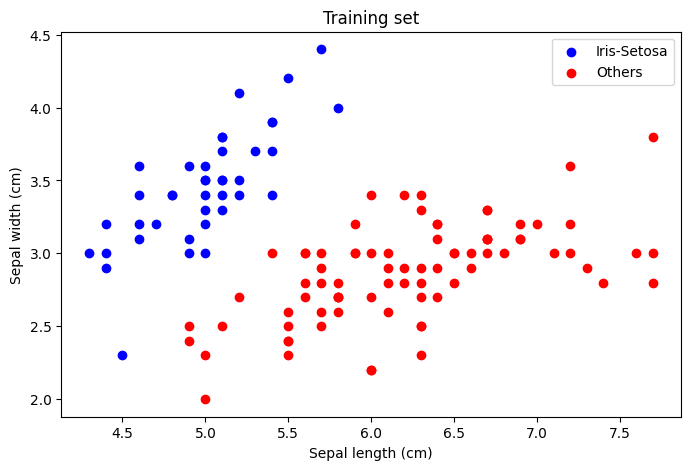

In [3]:
# Visualize the training data
labels = {0: 'Iris-Setosa', 1: 'Others'}
colors = ['blue', 'red']


def plot_data(x, y, labels, colours):
    for c in np.unique(y):
        inx = np.where(y == c)
        plt.scatter(x[inx, 0], x[inx, 1], label=labels[c], c=colours[c])
    plt.title("Training set")
    plt.xlabel("Sepal length (cm)")
    plt.ylabel("Sepal width (cm)")
    plt.legend()
    
plt.figure(figsize=(8, 5))
plot_data(x_train, y_train, labels, colors)
plt.show()

## Naive Bayes Theory

The Naive Bayes classifier uses Bayes' rule:

$$P(Y=k | X_1, X_2) = \frac{P(X_1, X_2 | Y=k) \cdot P(Y=k)}{P(X_1, X_2)}$$

The "naive" assumption is that features are independent given the class:

$$P(X_1, X_2 | Y=k) = P(X_1 | Y=k) \cdot P(X_2 | Y=k)$$

For prediction, we choose the class with maximum posterior probability:

$$\hat{Y} = \arg\max_k P(Y=k | X_1, X_2) \propto P(X_1 | Y=k) \cdot P(X_2 | Y=k) \cdot P(Y=k)$$

## Exercise 1: Compute the Class Prior

The prior probability is simply the proportion of samples in each class:

$$P(Y=k) = \frac{\text{number of samples in class } k}{\text{total number of samples}}$$

In [4]:
def compute_prior(y):
    """
    Compute prior probabilities P(Y=k) for each class.
    
    Args:
        y: array of labels, shape (n_samples,)
    
    Returns:
        priors: array of prior probabilities, shape (n_classes,)
    """
    # Count occurrences of each class
    unique_classes, counts = np.unique(y, return_counts=True)
    
    # Compute proportions
    priors = counts / len(y)
    
    return priors

Prior probabilities: [0.33333333 0.66666667]
P(Setosa) = 0.333
P(Others) = 0.667


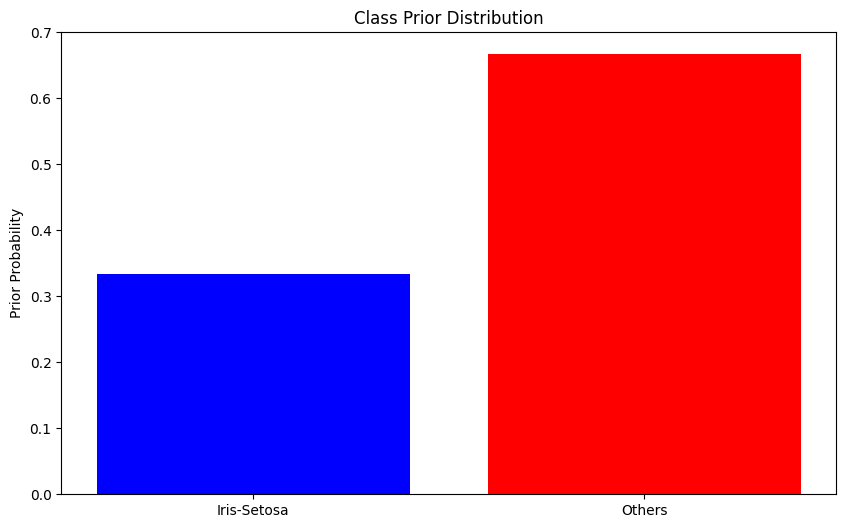

In [5]:
# Test your function
priors = compute_prior(y_train)
print(f"Prior probabilities: {priors}")
print(f"P(Setosa) = {priors[0]:.3f}")
print(f"P(Others) = {priors[1]:.3f}")

# Visualize
plt.bar([0, 1], priors, color=colors)
plt.xticks([0, 1], labels.values())
plt.ylabel("Prior Probability")
plt.title("Class Prior Distribution")
plt.show()

## Exercise 2: Compute Class-Conditional Parameters

We assume each feature follows a Gaussian distribution for each class:

$$P(X_i | Y=k) = \mathcal{N}(\mu_{ik}, \sigma_{ik}^2)$$

We estimate these parameters using maximum likelihood:

$$\mu_{ik} = \frac{1}{n_k} \sum_{j: y_j=k} x_{ij}$$

$$\sigma_{ik}^2 = \frac{1}{n_k} \sum_{j: y_j=k} (x_{ij} - \mu_{ik})^2$$

In [6]:
def compute_gaussian_params(x, y):
    """
    Compute mean and std for each feature in each class.
    
    Args:
        x: array of features, shape (n_samples, n_features)
        y: array of labels, shape (n_samples,)
    
    Returns:
        means: array of means, shape (n_classes, n_features)
        stds: array of standard deviations, shape (n_classes, n_features)
    """
    n_classes = len(np.unique(y))
    n_features = x.shape[1]
    
    means = np.zeros((n_classes, n_features))
    stds = np.zeros((n_classes, n_features))
    
    for k in range(n_classes):
        # Get samples belonging to class k
        x_k = x[y == k]
        
        # Compute mean and std for each feature
        means[k] = np.mean(x_k, axis=0)
        stds[k] = np.std(x_k, axis=0)
    
    return means, stds

In [7]:
# Test your function
means, stds = compute_gaussian_params(x_train, y_train)

print("Class-conditional parameters:")
print(f"\nClass 0 (Setosa):")
print(f"  Feature 0: mean={means[0,0]:.3f}, std={stds[0,0]:.3f}")
print(f"  Feature 1: mean={means[0,1]:.3f}, std={stds[0,1]:.3f}")
print(f"\nClass 1 (Others):")
print(f"  Feature 0: mean={means[1,0]:.3f}, std={stds[1,0]:.3f}")
print(f"  Feature 1: mean={means[1,1]:.3f}, std={stds[1,1]:.3f}")

Class-conditional parameters:

Class 0 (Setosa):
  Feature 0: mean=4.990, std=0.352
  Feature 1: mean=3.452, std=0.391

Class 1 (Others):
  Feature 0: mean=6.219, std=0.667
  Feature 1: mean=2.866, std=0.331


## Exercise 3: Implement the Prediction Function

To make predictions, we compute the log posterior for each class:

$$\log P(Y=k | X) \propto \log P(Y=k) + \sum_{i=1}^2 \log P(X_i | Y=k)$$

We use log probabilities for numerical stability.

In [8]:
def predict_naive_bayes(x, priors, means, stds):
    """
    Predict class labels using Naive Bayes.
    
    Args:
        x: array of features, shape (n_samples, n_features)
        priors: prior probabilities, shape (n_classes,)
        means: class means, shape (n_classes, n_features)
        stds: class stds, shape (n_classes, n_features)
    
    Returns:
        predictions: array of predicted labels, shape (n_samples,)
    """
    n_samples = x.shape[0]
    n_classes = len(priors)
    n_features = x.shape[1]
    
    # Initialize log posteriors
    log_posteriors = np.zeros((n_samples, n_classes))
    
    for k in range(n_classes):
        # Start with log prior
        log_posteriors[:, k] = np.log(priors[k])
        
        # Add log likelihood for each feature
        for j in range(n_features):
            log_posteriors[:, k] += norm.logpdf(x[:, j], means[k, j], stds[k, j])
    
    # Return class with maximum log posterior
    predictions = np.argmax(log_posteriors, axis=1)
    
    return predictions

In [9]:
# Test your prediction function
predictions = predict_naive_bayes(x_test, priors, means, stds)

accuracy = accuracy_score(y_test, predictions)
print(f"Test Accuracy: {accuracy:.4f}")

Test Accuracy: 1.0000


## Visualize Decision Boundary

In [10]:
dtype = torch.float32
def get_meshgrid(x0_range, x1_range, num_points=100):
    x0 = np.linspace(x0_range[0], x0_range[1], num_points)
    x1 = np.linspace(x1_range[0], x1_range[1], num_points)
    return np.meshgrid(x0, x1)

def contour_plot(x0_range, x1_range, logprob_fn, batch_shape, colours, levels=None, num_points=100, dtype=dtype):
    X0, X1 = get_meshgrid(x0_range, x1_range, num_points=num_points)
    Z = torch.exp(logprob_fn(torch.tensor(np.expand_dims(np.array([X0.ravel(), X1.ravel()]).T, 1), dtype=dtype)))
    Z = Z.detach().numpy().T.reshape(batch_shape, *X0.shape)
    for batch in np.arange(batch_shape):
        if levels:
            plt.contourf(X0, X1, Z[batch], alpha=0.2, colors=colours, levels=levels)
        else:
            plt.contour(X0, X1, Z[batch], colors=colours[batch], alpha=0.3)

def nb_log_pred(x):
    """Naive Bayes predicted label on the mesh, in log-space (contour_plot applies exp)."""
    pred = predict_naive_bayes(x.squeeze(1).numpy(), priors, means, stds)
    return torch.log(torch.tensor(pred, dtype=dtype))

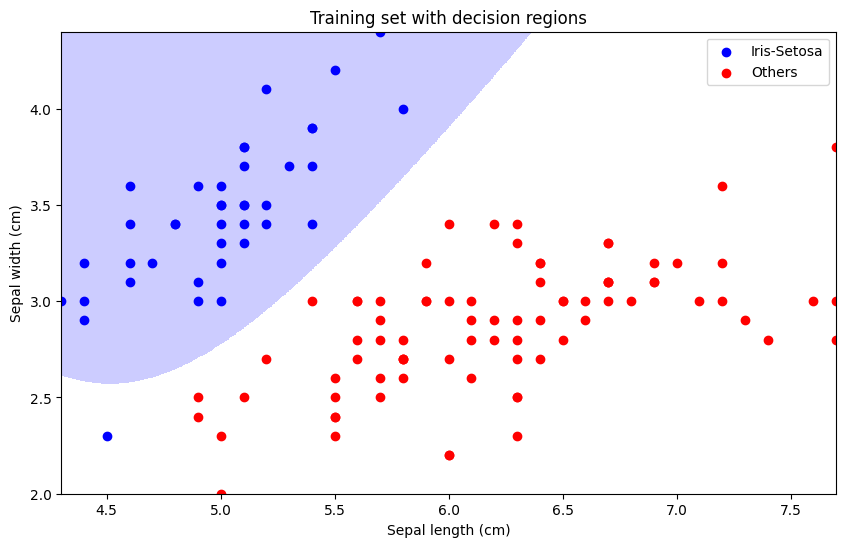

In [11]:
plot_data(x_train, y_train, labels, colors)
x0_min, x0_max = x_train[:, 0].min(), x_train[:, 0].max()
x1_min, x1_max = x_train[:, 1].min(), x_train[:, 1].max()
contour_plot((x0_min, x0_max), (x1_min, x1_max), 
             nb_log_pred,
             1, colors, levels=[-0.5, 0.5],
             num_points=500)
plt.title("Training set with decision regions")
plt.show()

## Compare with sklearn's Implementation

In [12]:
from sklearn.naive_bayes import GaussianNB

# Train sklearn's Naive Bayes
sklearn_nb = GaussianNB()
sklearn_nb.fit(x_train, y_train)
sklearn_pred = sklearn_nb.predict(x_test)
sklearn_accuracy = accuracy_score(y_test, sklearn_pred)

print(f"Your implementation accuracy: {accuracy:.4f}")
print(f"Sklearn implementation accuracy: {sklearn_accuracy:.4f}")
print(f"\nDifference: {abs(accuracy - sklearn_accuracy):.4f}")

Your implementation accuracy: 1.0000
Sklearn implementation accuracy: 1.0000

Difference: 0.0000


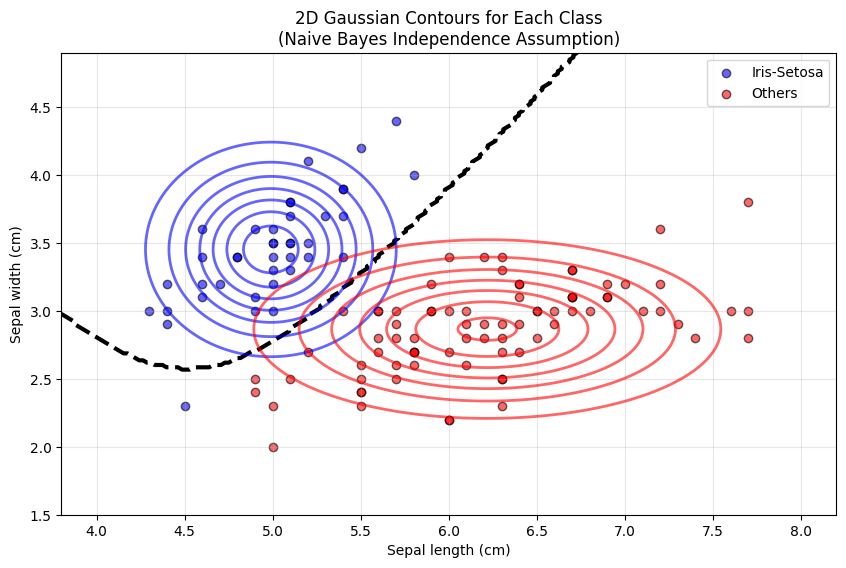

In [13]:
from scipy.stats import multivariate_normal
import numpy as np
import matplotlib.pyplot as plt

# Assuming you already have: x_train, y_train, means, stds, labels, colors

plt.figure(figsize=(10, 6))

# Plot training data points
for c in [0, 1]:
    mask = y_train == c
    plt.scatter(x_train[mask, 0], x_train[mask, 1], 
                label=labels[c], c=colors[c], alpha=0.6, edgecolor='k')

# Create mesh grid for contour plot
x0_min, x0_max = x_train[:, 0].min() - 0.5, x_train[:, 0].max() + 0.5
x1_min, x1_max = x_train[:, 1].min() - 0.5, x_train[:, 1].max() + 0.5
xx0, xx1 = np.meshgrid(np.linspace(x0_min, x0_max, 200),
                        np.linspace(x1_min, x1_max, 200))
mesh_points = np.c_[xx0.ravel(), xx1.ravel()]

# Compute predictions on the mesh
Z_pred = predict_naive_bayes(mesh_points, priors, means, stds)
Z_pred = Z_pred.reshape(xx0.shape)

# Plot the boundary at level 0.5 (between classes 0 and 1)
plt.contour(xx0, xx1, Z_pred, levels=[0.5], colors='black', 
            linewidths=3, linestyles='--')

# Plot contours for each class
for k in range(2):
    # Create diagonal covariance matrix (Naive Bayes independence assumption)
    cov = np.diag(stds[k]**2)
    
    # Create multivariate normal distribution
    mvn = multivariate_normal(mean=means[k], cov=cov)
    
    # Evaluate probability density on mesh
    Z = mvn.pdf(mesh_points).reshape(xx0.shape)
    
    # Plot contours
    plt.contour(xx0, xx1, Z, colors=colors[k], alpha=0.6, linewidths=2)

plt.xlabel("Sepal length (cm)")
plt.ylabel("Sepal width (cm)")
plt.title("2D Gaussian Contours for Each Class\n(Naive Bayes Independence Assumption)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

## Logistic regression

Now for the same classification task, we will use the logistic regression algorithm seen in the course.

In [15]:
class LogisticRegression(torch.nn.Module):
    def __init__(self, input_dim, output_dim):
        super(LogisticRegression, self).__init__()
        self.linear = torch.nn.Linear(input_dim, output_dim)
        
    def forward(self, x):
        return torch.sigmoid(self.linear(x))

epochs = 4000
input_dim = 2 # Two inputs x1 and x2 
output_dim = 1 
learning_rate = 0.01

model = LogisticRegression(input_dim,output_dim)

criterion = torch.nn.BCELoss()

optimizer = torch.optim.SGD(model.parameters(), lr=learning_rate)

In [16]:
def train(model,criterion,optimizer,x_train,y_train,x_test,y_test,n_epochs=epochs,freq_print=200):
    losses = []
    losses_test = []
    Iterations = []
    iter = 0
    for epoch in range(n_epochs):
        outputs = model(x_train)
        
        loss = criterion(outputs.squeeze(), y_train) 
        optimizer.zero_grad() # Setting our stored gradients equal to zero
        loss.backward() # Computes the gradient of the given tensor w.r.t. graph leaves 
        optimizer.step() # Updates weights and biases with the optimizer (SGD)
        iter+=1
        if iter%freq_print==0:
            # calculate Accuracy
            with torch.no_grad():
                # Calculating the loss and accuracy for the test dataset
                correct_test = 0
                total_test = 0
                outputs_test = torch.squeeze(model(x_test))
                loss_test = criterion(outputs_test, y_test)

                predicted_test = outputs_test.round().detach().numpy()
                total_test += y_test.size(0)
                correct_test += np.sum(predicted_test == y_test.detach().numpy())
                accuracy_test = 100 * correct_test/total_test
                losses_test.append(loss_test.item())
                
                # Calculating the loss and accuracy for the train dataset
                total = 0
                correct = 0
                total += y_train.size(0)
                correct += np.sum(torch.squeeze(outputs).round().detach().numpy() == y_train.detach().numpy())
                accuracy = 100 * correct/total
                losses.append(loss.item())
                Iterations.append(iter)

                print(f"Iteration: {iter}. \nTest - Loss: {loss_test.item()}. Accuracy: {accuracy_test}")
                print(f"Train -  Loss: {loss.item()}. Accuracy: {accuracy}\n")
    return losses, losses_test, Iterations

In [17]:
dtype = torch.float32
x_trt = torch.tensor(x_train, dtype=dtype)
x_tst = torch.tensor(x_test, dtype=dtype)
y_trt = torch.tensor(y_train, dtype=dtype)
y_tst = torch.tensor(y_test, dtype=dtype)

losses, losses_test, Iterations = train(model,criterion,optimizer,x_trt,y_trt,x_tst,y_tst)

Iteration: 200. 
Test - Loss: 0.4413512647151947. Accuracy: 70.0
Train -  Loss: 0.43007519841194153. Accuracy: 76.66666666666667

Iteration: 400. 
Test - Loss: 0.39211809635162354. Accuracy: 80.0
Train -  Loss: 0.37781187891960144. Accuracy: 90.0

Iteration: 600. 
Test - Loss: 0.35350301861763. Accuracy: 80.0
Train -  Loss: 0.3372839093208313. Accuracy: 94.16666666666667

Iteration: 800. 
Test - Loss: 0.32255756855010986. Accuracy: 86.66666666666667
Train -  Loss: 0.3051949441432953. Accuracy: 95.83333333333333

Iteration: 1000. 
Test - Loss: 0.29726019501686096. Accuracy: 93.33333333333333
Train -  Loss: 0.27928128838539124. Accuracy: 97.5

Iteration: 1200. 
Test - Loss: 0.2762111723423004. Accuracy: 100.0
Train -  Loss: 0.25797775387763977. Accuracy: 97.5

Iteration: 1400. 
Test - Loss: 0.25842344760894775. Accuracy: 100.0
Train -  Loss: 0.2401849329471588. Accuracy: 97.5

Iteration: 1600. 
Test - Loss: 0.2431875318288803. Accuracy: 100.0
Train -  Loss: 0.22511616349220276. Accuracy:

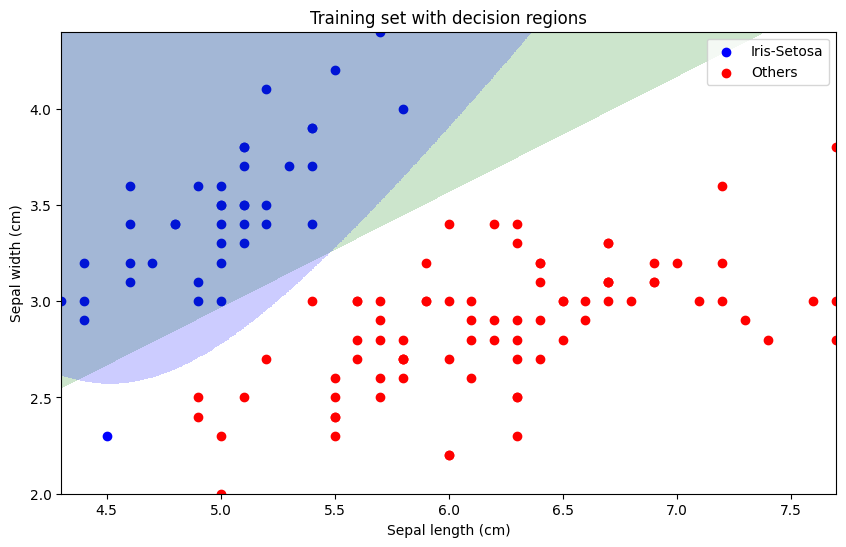

In [18]:
plt.figure(figsize=(10, 6))
plot_data(x_train, y_train, labels, colors)
x0_min, x0_max = x_train[:, 0].min(), x_train[:, 0].max()
x1_min, x1_max = x_train[:, 1].min(), x_train[:, 1].max()
model.eval()
contour_plot((x0_min, x0_max), (x1_min, x1_max), 
             lambda x: torch.log(model(x)), 
             1, ['green'], levels=[-0.5, 0.5],
             num_points=500)
contour_plot((x0_min, x0_max), (x1_min, x1_max), 
             nb_log_pred,
             1, colors, levels=[-0.5, 0.5],
             num_points=500)
plt.title("Training set with decision regions")
plt.show()